# Portfolio Credit Risk: Vasicek / IRB Capital & CreditMetrics

The regulatory capital formula treats every loan as if it sat in an endlessly diversified portfolio. A development lender's book is nothing like that: a few large names, shared sectors, and defaults that cluster in a crisis. This notebook builds a real loan book and compares the regulatory number with an economic capital model that sees those concentrations.

**What it does.** It builds a $7bn corporate loan book on 60 real U.S. companies and estimates each obligor's PD with a Merton (KMV-style) model from its equity price and balance sheet. Asset correlations come from a PCA factor model of equity returns.

It then compares Basel IRB capital with Monte Carlo economic capital, in default mode (Gaussian and Student-t copulas) and in mark-to-market (CreditMetrics-style) mode, and splits the tail risk by obligor and sector to show where concentration sits.

**Data.** Three years of daily prices (Yahoo Finance), total and current liabilities and shares outstanding from each company's latest 10-K/10-Q (SEC EDGAR XBRL API), and the 1-year Treasury yield (FRED).

**Methods.** The Merton structural model solved for asset value and volatility, distance to default, a PCA factor model with systematic R², and Basel IRB (ASRF/Vasicek) risk weights with maturity adjustment.

The simulations use multi-factor Gaussian and t-copula Monte Carlo with stochastic LGD, Merton-consistent rating migration and loan revaluation, expected-shortfall (Euler) risk contributions and HHI concentration.

**Key output.** Obligor PDs and correlations, IRB capital against economic capital under each model, the loss distribution, and the obligors and sectors that drive the tail.

## 1. Why portfolio models matter beyond the IRB formula

The Basel IRB formula is the **Vasicek asymptotic single risk factor (ASRF)** model. It assumes an infinitely granular portfolio and a single systematic factor, so each loan's capital depends only on its own PD, LGD, maturity and a regulatory correlation.

That makes capital **additive** and independent of the rest of the portfolio, which is why regulators chose it. But it ignores exactly what a credit-risk officer at a development lender worries about:

- **name concentration:** a few large exposures (a development bank's book is far from granular);
- **sector concentration:** obligors that share more than one factor;
- **fat tails:** defaults that cluster more in crises than a Gaussian copula implies;
- **migration risk:** value lost when credit quality worsens without a default.

This is why Basel Pillar 2 asks for an internal economic capital model. This notebook builds one next to the IRB number.

## 2. Theory in brief

**Merton PD.** Equity is a call on the firm's assets $V$ with strike equal to the default point $D$:
$E=V\,N(d_1)-De^{-rT}N(d_2)$ and $\sigma_E E=N(d_1)\,\sigma_V V$, with $d_{1,2}=\dfrac{\ln(V/D)+(r\pm\sigma_V^2/2)T}{\sigma_V\sqrt T}$. The two equations give $V$ and $\sigma_V$; the **distance to default** is $DD=d_2$ and $PD=N(-DD)$. Following KMV, $D$ = current liabilities + ½ long-term liabilities.

**Factor model.** Standardised asset returns $X_i=\sum_k\beta_{ik}Z_k+\sqrt{1-R_i^2}\,\varepsilon_i$, with the factors $Z_k$ from a PCA of equity returns; $R_i^2=\sum_k\beta_{ik}^2$ is the obligor's asset correlation with the systematic factors. Obligor $i$ defaults when $X_i<N^{-1}(PD_i)$.

**IRB capital (corporate).** $K=LGD\left[N\!\left(\dfrac{N^{-1}(PD)+\sqrt{\rho}\,N^{-1}(0.999)}{\sqrt{1-\rho}}\right)-PD\right]\dfrac{1+(M-2.5)b}{1-1.5b}$, with $\rho=0.12\,\dfrac{1-e^{-50PD}}{1-e^{-50}}+0.24\left(1-\dfrac{1-e^{-50PD}}{1-e^{-50}}\right)$ and $b=(0.11852-0.05478\ln PD)^2$. Capital $=K\cdot EAD$; RWA $=12.5\,K\cdot EAD$.

**Economic capital** is the 99.9% loss quantile minus expected loss of the simulated loss distribution. **Euler (expected-shortfall) contributions**, $E[L_i\mid L\ge \text{VaR}]$, add up to the portfolio ES and show who drives the tail.

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import yfinance as yf
from scipy import optimize, stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

SEED = 2026
SEC_USER_AGENT = os.getenv("SEC_USER_AGENT", "").strip()
if not SEC_USER_AGENT:
    raise RuntimeError(
        "SEC_USER_AGENT not found in .env (SEC requires 'Name email@domain' in"
        " the User-Agent)."
    )
SEC_HEADERS = {
    "User-Agent": SEC_USER_AGENT,
    "Accept-Encoding": "gzip, deflate",
}

# 60 U.S. non-financial obligors across ten sectors, from strong investment
# grade to high yield
OBLIGORS = {
    "Technology": ["AAPL", "MSFT", "ORCL", "IBM", "INTC", "HPQ"],
    "Health care": ["JNJ", "PFE", "MRK", "BAX", "VTRS", "HCA"],
    "Consumer staples": ["PG", "KO", "PEP", "KHC", "CAG", "GIS"],
    "Retail": ["WMT", "TGT", "HD", "LOW", "KSS", "M"],
    "Autos & industrials": ["F", "GM", "GT", "CAT", "EMR", "BA"],
    "Travel & leisure": ["AAL", "UAL", "DAL", "CCL", "RCL", "NCLH"],
    "Energy": ["XOM", "CVX", "OXY", "DVN", "APA", "HAL"],
    "Telecom & media": ["T", "VZ", "CMCSA", "CHTR", "DIS", "NFLX"],
    "Utilities": ["NEE", "DUK", "SO", "PCG", "AES", "EIX"],
    "Materials": ["DOW", "LYB", "CLF", "FCX", "NEM", "IP"],
}
SECTOR_OF = {t: s for s, ts in OBLIGORS.items() for t in ts}
TICKERS = list(SECTOR_OF)
PRICE_START = (
    pd.Timestamp.today() - pd.DateOffset(years=3, days=10)
).strftime("%Y-%m-%d")
# Basel III final-reform PD floor for corporates (5 bp)
PD_FLOOR = 0.0005
# F-IRB senior unsecured LGD for non-financial corporates; stochastic in the
# simulation
LGD_MEAN, LGD_SD = 0.40, 0.20
MATURITY = 3.0  # years, all loans
N_FACTORS = 3
N_SIMS, CHUNK = 400_000, 50_000
T_DF = 4  # degrees of freedom of the t-copula

print(f"yfinance {yf.__version__} · run on {dt.date.today():%Y-%m-%d}")

yfinance 1.7.0 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 4. Data: prices, balance sheets and the risk-free rate

Prices come from Yahoo Finance. Balance-sheet items come from the SEC's XBRL *company facts* API: the latest reported `LiabilitiesCurrent`, `Liabilities` (or, when a company does not tag it, total liabilities and equity minus equity) and `EntityCommonStockSharesOutstanding` summed over share classes (falling back to the balance-sheet share count when the cover-page figure is stale). Companies with missing data are dropped and reported.

In [3]:
def fetch_prices():
    px = yf.download(
        TICKERS, start=PRICE_START, auto_adjust=True, progress=False
    )["Close"]
    px.index = pd.to_datetime(px.index).tz_localize(None)
    px.index.name, px.columns.name = "date", None
    return px.reset_index()


def fetch_cik_map():
    r = requests.get(
        "https://www.sec.gov/files/company_tickers.json",
        headers=SEC_HEADERS,
        timeout=60,
    )
    r.raise_for_status()
    return pd.DataFrame(r.json()).T.assign(
        cik=lambda d: d["cik_str"].astype(int)
    )[["ticker", "cik", "title"]]


def latest_fact(facts, taxonomy, tag, unit):
    try:
        obs = pd.DataFrame(facts["facts"][taxonomy][tag]["units"][unit])
    except KeyError:
        return np.nan, None
    obs = obs[obs["form"].isin(["10-K", "10-Q", "10-K/A", "10-Q/A"])]
    if obs.empty:
        return np.nan, None
    obs["end"] = pd.to_datetime(obs["end"])
    last = obs["end"].max()
    return (
        obs.loc[obs["end"] == last, "val"].drop_duplicates().sum()
        if tag.startswith("EntityCommon")
        else obs.loc[obs["end"] == last].sort_values("filed")["val"].iloc[-1]
    ), last


def fetch_balance_sheets():
    ciks = fetch_cik_map().set_index("ticker")["cik"]
    rows = []
    for t in TICKERS:
        if t not in ciks:
            continue
        r = requests.get(
            f"https://data.sec.gov/api/xbrl/companyfacts/CIK{ciks[t]:010d}.json",
            headers=SEC_HEADERS,
            timeout=60,
        )
        if r.status_code != 200:
            continue
        f = r.json()
        cur, d_cur = latest_fact(f, "us-gaap", "LiabilitiesCurrent", "USD")
        tot, d_tot = latest_fact(f, "us-gaap", "Liabilities", "USD")
        if np.isnan(tot):
            le, _ = latest_fact(
                f, "us-gaap", "LiabilitiesAndStockholdersEquity", "USD"
            )
            eq, _ = latest_fact(
                f,
                "us-gaap",
                "StockholdersEquityIncludingPortionAttributableToNoncontrollingInterest",
                "USD",
            )
            if np.isnan(eq):
                eq, _ = latest_fact(f, "us-gaap", "StockholdersEquity", "USD")
            tot, d_tot = le - eq, d_cur
        sh, d_sh = latest_fact(
            f, "dei", "EntityCommonStockSharesOutstanding", "shares"
        )
        for tag in [
            "CommonStockSharesOutstanding",
            "WeightedAverageNumberOfSharesOutstandingBasic",
        ]:
            # cover-page count missing or stale
            if d_sh is None or (
                d_tot is not None and (d_tot - d_sh).days > 400
            ):
                alt, d_alt = latest_fact(f, "us-gaap", tag, "shares")
                if d_alt is not None and (d_sh is None or d_alt > d_sh):
                    sh, d_sh = alt, d_alt
        rows.append({
            "ticker": t,
            "company": f.get("entityName"),
            "current_liabilities": cur,
            "total_liabilities": tot,
            "shares": sh,
            "balance_sheet_date": d_tot,
            "shares_date": d_sh,
        })
        # SEC fair-access limit: 10 requests per second
        time.sleep(0.12)
    return pd.DataFrame(rows)


prices = (
    cached("yahoo_prices", fetch_prices, max_age_hours=24)
    .set_index("date")
    .sort_index()
)
prices = prices[prices.index < pd.Timestamp.today().normalize()].ffill(limit=3)
bs = cached(
    "sec_balance_sheets", fetch_balance_sheets, max_age_hours=24 * 7
).set_index("ticker")
r_1y = fred.get_series("DGS1").dropna().iloc[-1] / 100
EVAL_DATE = prices.index.max()
print(
    f"Prices to {EVAL_DATE:%Y-%m-%d} · 1-year Treasury {r_1y:.2%} · balance"
    f" sheets for {len(bs)} of {len(TICKERS)} obligors"
)

Prices to 2026-10-16 · 1-year Treasury 4.46% · balance sheets for 60 of 60 obligors


## 5. Merton PDs

Equity value = last price × shares outstanding; equity volatility = annualised standard deviation of the last 252 daily log returns. The two Merton equations are solved for asset value and asset volatility, with a one-year horizon. PDs below the 5 bp regulatory floor are floored.

In [4]:
logret = np.log(prices).diff()
rows, dropped = [], []
for t in TICKERS:
    if (
        t not in bs.index
        or t not in prices
        or prices[t].iloc[-252:].isna().mean() > 0.05
    ):
        dropped.append(t)
        continue
    b = bs.loc[t]
    stale = (
        pd.isna(b["shares_date"])
        or (b["balance_sheet_date"] - b["shares_date"]).days > 400
    )
    if stale or not (
        b["shares"] > 0
        and b["total_liabilities"] > 0
        and b["current_liabilities"] > 0
    ):
        # missing or stale share count: equity value unreliable
        dropped.append(t)
        continue
    E = prices[t].dropna().iloc[-1] * b["shares"]
    sE = logret[t].iloc[-252:].std() * np.sqrt(252)
    D = b["current_liabilities"] + 0.5 * (
        b["total_liabilities"] - b["current_liabilities"]
    )

    def eqs(x):
        V, sV = np.exp(x[0]), np.exp(x[1])
        d1 = (np.log(V / D) + (r_1y + sV**2 / 2)) / sV
        d2 = d1 - sV
        return [
            (V * stats.norm.cdf(d1) - D * np.exp(-r_1y) * stats.norm.cdf(d2))
            / E
            - 1,
            stats.norm.cdf(d1) * sV * V / (sE * E) - 1,
        ]

    sol, info, ok, _ = optimize.fsolve(
        eqs, [np.log(E + D), np.log(sE * E / (E + D))], full_output=True
    )
    V, sV = np.exp(sol)
    DD = (np.log(V / D) + (r_1y - sV**2 / 2)) / sV
    rows.append({
        "ticker": t,
        "sector": SECTOR_OF[t],
        "equity $bn": E / 1e9,
        "default point $bn": D / 1e9,
        "equity vol %": sE * 100,
        "asset value $bn": V / 1e9,
        "asset vol %": sV * 100,
        "leverage D/V %": D / V * 100,
        "DD": DD,
        "Merton PD %": stats.norm.cdf(-DD) * 100,
        "solved": ok == 1 and sV > 0.01 and V > D * 0.5,
    })
ob = pd.DataFrame(rows).set_index("ticker")
ob = ob[ob["solved"]].drop(columns="solved")
ob["PD %"] = np.maximum(ob["Merton PD %"], PD_FLOOR * 100)
print(
    f"{len(ob)} obligors priced · dropped: {dropped or 'none'} ·"
    f" {(ob['Merton PD %'] < PD_FLOOR * 100).sum()} at the 5 bp floor"
)
ob.sort_values("DD").round(2).head(15)

60 obligors priced · dropped: none · 44 at the 5 bp floor


,sector,equity $bn,default point $bn,equity vol %,asset value $bn,asset vol %,leverage D/V %,DD,Merton PD %,PD %
ticker,,,,,,,,,,
KSS,Retail,2.45,5.97,68.51,8.13,21.50,73.46,1.53,6.24,6.24
CLF,Materials,6.91,8.95,69.58,15.43,31.90,58.01,1.69,4.58,4.58
CHTR,Telecom & media,13.23,73.75,54.62,83.69,8.84,88.12,1.89,2.94,2.94
NCLH,Travel & leisure,6.91,13.88,54.60,20.17,18.91,68.81,2.12,1.71,1.71
GT,Autos & industrials,1.24,11.46,47.09,12.20,4.83,93.99,2.18,1.46,1.46
AAL,Travel & leisure,7.86,47.48,47.76,53.26,7.13,89.15,2.20,1.39,1.39
UAL,Travel & leisure,31.19,47.82,48.02,76.91,19.53,62.17,2.56,0.52,0.52
HPQ,Technology,27.06,40.99,44.99,66.26,18.40,61.86,2.76,0.29,0.29
INTC,Technology,453.20,67.48,76.24,517.71,66.76,13.03,2.79,0.27,0.27


## 6. Asset correlations from a PCA factor model

Weekly log returns over three years are standardised and decomposed with PCA. Each obligor's return is regressed on the first three standardised principal components; the loadings $\beta_{ik}$ define the factor model and $R_i^2$ its systematic share. Equity correlations are used as a proxy for asset correlations, the usual industry practice (KMV, CreditMetrics).

In [5]:
names = ob.index.tolist()
wk = (
    np.log(prices[names])
    .resample("W-FRI")
    .last()
    .diff()
    .dropna(how="all")
    .dropna(axis=0)
)
Zr = (wk - wk.mean()) / wk.std()
eigval, eigvec = np.linalg.eigh(np.corrcoef(Zr.T.values))
order = np.argsort(eigval)[::-1]
eigval, eigvec = eigval[order], eigvec[:, order]
scores = Zr.values @ eigvec[:, :N_FACTORS]
scores = scores / scores.std(axis=0)
# loadings: names x factors
B = np.linalg.lstsq(scores, Zr.values, rcond=None)[0].T
R2 = (B**2).sum(axis=1)
# keep idiosyncratic variance positive
scale = np.sqrt(np.minimum(R2, 0.95) / R2)
B, R2 = B * scale[:, None], np.minimum(R2, 0.95)
ob["PCA R² (asset correlation)"] = R2 * 100

pd_ = ob["PD %"].to_numpy() / 100
w = (1 - np.exp(-50 * pd_)) / (1 - np.exp(-50))
ob["Basel ρ %"] = (0.12 * w + 0.24 * (1 - w)) * 100
expl = pd.Series(
    eigval[:6] / eigval.sum() * 100, index=[f"PC{i + 1}" for i in range(6)]
).round(1)
print(f"{len(wk)} weeks · variance explained by PC1–PC6 (%): {expl.to_dict()}")
ob.groupby("sector")[
    ["PD %", "PCA R² (asset correlation)", "Basel ρ %"]
].mean().round(2)

157 weeks · variance explained by PC1–PC6 (%): {'PC1': 20.2, 'PC2': 10.8, 'PC3': 9.1, 'PC4': 4.0, 'PC5': 3.7, 'PC6': 3.4}


,PD %,PCA R² (asset correlation),Basel ρ %
sector,,,
Autos & industrials,0.30,35.55,22.62
Consumer staples,0.05,49.80,23.70
Energy,0.05,76.34,23.70
Health care,0.05,29.98,23.70
Materials,0.82,36.47,21.87
Retail,1.08,32.89,21.83
Technology,0.14,22.39,23.18
Telecom & media,0.53,26.41,22.21
Travel & leisure,0.65,53.46,21.14


## 7. The loan book and IRB capital

Exposures are drawn once from a lognormal distribution (median about $85mm, a few large tickets), so the book has realistic name concentration. All loans are senior unsecured with a three-year maturity.

In [6]:
rng = np.random.default_rng(SEED)
ob["EAD $mm"] = np.round(np.exp(rng.normal(np.log(85), 0.6, len(ob))), 0)
EAD = ob["EAD $mm"].to_numpy()
G = stats.norm.ppf
rho = ob["Basel ρ %"].to_numpy() / 100
bm = (0.11852 - 0.05478 * np.log(pd_)) ** 2
MA = (1 + (MATURITY - 2.5) * bm) / (1 - 1.5 * bm)
K = (
    LGD_MEAN
    * (
        stats.norm.cdf((G(pd_) + np.sqrt(rho) * G(0.999)) / np.sqrt(1 - rho))
        - pd_
    )
    * MA
)
ob["IRB K %"] = K * 100
ob["IRB capital $mm"] = K * EAD
ob["EL $mm"] = pd_ * LGD_MEAN * EAD
hhi = ((EAD / EAD.sum()) ** 2).sum()
irb = {
    "EAD $mm": EAD.sum(),
    "EL $mm": ob["EL $mm"].sum(),
    "IRB capital $mm": ob["IRB capital $mm"].sum(),
    "RWA $mm": 12.5 * ob["IRB capital $mm"].sum(),
    "average risk weight %": (
        12.5 * ob["IRB capital $mm"].sum() / EAD.sum() * 100
    ),
    "HHI": hhi,
    "effective number of names": 1 / hhi,
}
pd.Series(irb).round(2).to_frame("portfolio")

,portfolio
EAD $mm,"7,085.00"
EL $mm,8.15
IRB capital $mm,170.94
RWA $mm,"2,136.77"
average risk weight %,30.16
HHI,0.03
effective number of names,38.24


## 8. Monte Carlo economic capital

Five views of the same book, 400,000 one-year scenarios each:

| Run | Correlation structure | Copula | Mode |
|---|---|---|---|
| A | Basel ρ, one factor | Gaussian | default |
| B | PCA, three factors | Gaussian | default |
| C | PCA, three factors | Student-t (ν = 4) | default |
| D | PCA, three factors | Gaussian | mark-to-market |

LGD is drawn from a Beta distribution with mean 40% and standard deviation 20%, independently per default. In **mark-to-market mode**, a surviving loan is revalued with its new one-year PD: the obligor's asset return moves its distance to default to $DD_T=X_i-N^{-1}(PD_i)$, the new PD is $N(-DD_T)$, and the loan is discounted for its remaining two years at a credit spread of $-\ln(1-PD_T)\cdot LGD$.

The loss is measured against the expected value of a surviving loan, so migration adds volatility but not a spurious expected loss. That is CreditMetrics with Merton-consistent migrations instead of a rating transition matrix.

In [7]:
a_beta = LGD_MEAN * (LGD_MEAN * (1 - LGD_MEAN) / LGD_SD**2 - 1)
b_beta = (1 - LGD_MEAN) * (LGD_MEAN * (1 - LGD_MEAN) / LGD_SD**2 - 1)
thr_g, thr_t = G(pd_), stats.t.ppf(pd_, T_DF)
REM = MATURITY - 1


def value_at_horizon(X):
    """
    Value of a surviving loan per $ of EAD when its standardised asset return
    is X (Merton migration).
    """
    # new one-year PD: N(-(DD_0 + X))
    pd_T = np.clip(stats.norm.cdf(thr_g - X), PD_FLOOR, 0.9999)
    return np.exp(np.log(1 - pd_T) * LGD_MEAN * REM)


# Expected horizon value given survival, by Gauss-Hermite quadrature: the
# benchmark the MTM loss is measured from.
# (A Merton obligor's forward PD rises on average, so measuring from today's PD
# would book that drift as a loss.)
gh_x, gh_w = np.polynomial.hermite_e.hermegauss(200)
gh_w = gh_w / gh_w.sum()
alive = gh_x[:, None] >= thr_g[None, :]
V_surv = (gh_w[:, None] * alive * value_at_horizon(gh_x[:, None])).sum(0) / (
    gh_w[:, None] * alive
).sum(0)


def simulate(run, n=N_SIMS):
    losses, contrib_parts = [], []
    rng = np.random.default_rng(SEED + "ABCD".index(run))
    for _ in range(n // CHUNK):
        if run == "A":
            Z = rng.standard_normal((CHUNK, 1))
            X = Z * np.sqrt(rho) + rng.standard_normal(
                (CHUNK, len(pd_))
            ) * np.sqrt(1 - rho)
        else:
            Z = rng.standard_normal((CHUNK, N_FACTORS))
            X = Z @ B.T + rng.standard_normal((CHUNK, len(pd_))) * np.sqrt(
                1 - R2
            )
        if run == "C":
            X = X / np.sqrt(rng.chisquare(T_DF, (CHUNK, 1)) / T_DF)
            default = X < thr_t
        else:
            default = X < thr_g
        lgd = rng.beta(a_beta, b_beta, (CHUNK, len(pd_)))
        L = default * lgd * EAD
        if run == "D":
            # gain (negative loss) if credit quality improves
            mtm = EAD * (V_surv - value_at_horizon(X))
            L = np.where(default, L, mtm)
        losses.append(L.sum(axis=1))
        contrib_parts.append(L.astype(np.float32))
    return np.concatenate(losses), np.vstack(contrib_parts)


summary, tails, sims = {}, {}, {}
for run, label in [
    ("A", "A · Basel ρ, 1 factor"),
    ("B", "B · PCA, Gaussian"),
    ("C", "C · PCA, t-copula"),
    ("D", "D · PCA, mark-to-market"),
]:
    L, Li = simulate(run)
    var = np.quantile(L, 0.999)
    tail = L >= var
    summary[label] = {
        "EL $mm": L.mean(),
        "VaR 99.9% $mm": var,
        "ES 99.9% $mm": L[tail].mean(),
        "economic capital $mm": var - L.mean(),
        "EC / IRB capital": (var - L.mean()) / irb["IRB capital $mm"],
        "P(loss > IRB capital + EL) %": (
            L > irb["IRB capital $mm"] + irb["EL $mm"]
        ).mean() * 100,
    }
    tails[label] = Li[tail].mean(axis=0)
    sims[label] = L
summary = pd.DataFrame(summary).T
summary.loc["IRB (ASRF formula)"] = {
    "EL $mm": irb["EL $mm"],
    "economic capital $mm": irb["IRB capital $mm"],
    "EC / IRB capital": 1.0,
}
summary.round(2)

,EL $mm,VaR 99.9% $mm,ES 99.9% $mm,economic capital $mm,EC / IRB capital,P(loss > IRB capital + EL) %
"A · Basel ρ, 1 factor",8.20,229.89,305.75,221.69,1.30,0.22
"B · PCA, Gaussian",8.13,259.18,328.65,251.05,1.47,0.33
"C · PCA, t-copula",8.21,515.75,814.40,507.54,2.97,0.66
"D · PCA, mark-to-market",6.97,564.96,662.96,557.99,3.26,5.14
IRB (ASRF formula),8.15,NaN,NaN,170.94,1.00,NaN


### Who drives the tail?

Expected-shortfall contributions from run B (PCA, Gaussian), by obligor and by sector, against each obligor's IRB capital. A ratio above one means the portfolio model charges the name more than the additive IRB formula does, because of its size, its correlation with the rest of the book, or both.

In [8]:
ob["ES contribution $mm"] = tails["B · PCA, Gaussian"]
ob["ES contribution / IRB capital"] = (
    ob["ES contribution $mm"] / ob["IRB capital $mm"]
)
by_sector = ob.groupby("sector").agg(**{
    "EAD $mm": ("EAD $mm", "sum"),
    "IRB capital $mm": ("IRB capital $mm", "sum"),
    "ES contribution $mm": ("ES contribution $mm", "sum"),
    "mean PD %": ("PD %", "mean"),
})
by_sector["share of ES %"] = (
    by_sector["ES contribution $mm"]
    / by_sector["ES contribution $mm"].sum()
    * 100
)
by_sector["share of EAD %"] = (
    by_sector["EAD $mm"] / by_sector["EAD $mm"].sum() * 100
)
display(by_sector.sort_values("share of ES %", ascending=False).round(2))
ob.sort_values("ES contribution $mm", ascending=False)[[
    "sector",
    "EAD $mm",
    "PD %",
    "PCA R² (asset correlation)",
    "IRB capital $mm",
    "ES contribution $mm",
    "ES contribution / IRB capital",
]].head(12).round(2)

,EAD $mm,IRB capital $mm,ES contribution $mm,mean PD %,share of ES %,share of EAD %
sector,,,,,,
Utilities,"1,533.00",25.42,98.63,0.06,30.01,21.64
Travel & leisure,719.00,32.37,89.45,0.65,27.22,10.15
Telecom & media,873.00,24.33,48.49,0.53,14.75,12.32
Retail,458.00,15.12,25.24,1.08,7.68,6.46
Autos & industrials,760.00,17.34,20.67,0.30,6.29,10.73
Materials,566.00,16.40,18.74,0.82,5.70,7.99
Technology,570.00,14.31,13.33,0.14,4.06,8.05
Energy,540.00,8.63,5.61,0.05,1.71,7.62
Consumer staples,501.00,8.00,4.97,0.05,1.51,7.07


,sector,EAD $mm,PD %,PCA R² (asset correlation),IRB capital $mm,ES contribution $mm,ES contribution / IRB capital
ticker,,,,,,,
DUK,Utilities,563.00,0.05,46.75,8.99,68.71,7.64
UAL,Travel & leisure,191.00,0.52,53.96,10.40,36.31,3.49
NCLH,Travel & leisure,128.00,1.71,48.48,10.57,26.20,2.48
CHTR,Telecom & media,131.00,2.94,25.27,12.48,26.12,2.09
NEE,Utilities,395.00,0.05,34.39,6.31,24.77,3.93
DIS,Telecom & media,315.00,0.05,32.72,5.03,18.46,3.67
KSS,Retail,74.00,6.24,35.59,8.83,17.78,2.01
CCL,Travel & leisure,168.00,0.16,55.49,5.08,17.02,3.35
CLF,Materials,71.00,4.58,26.55,7.65,11.96,1.56


## 9. Charts

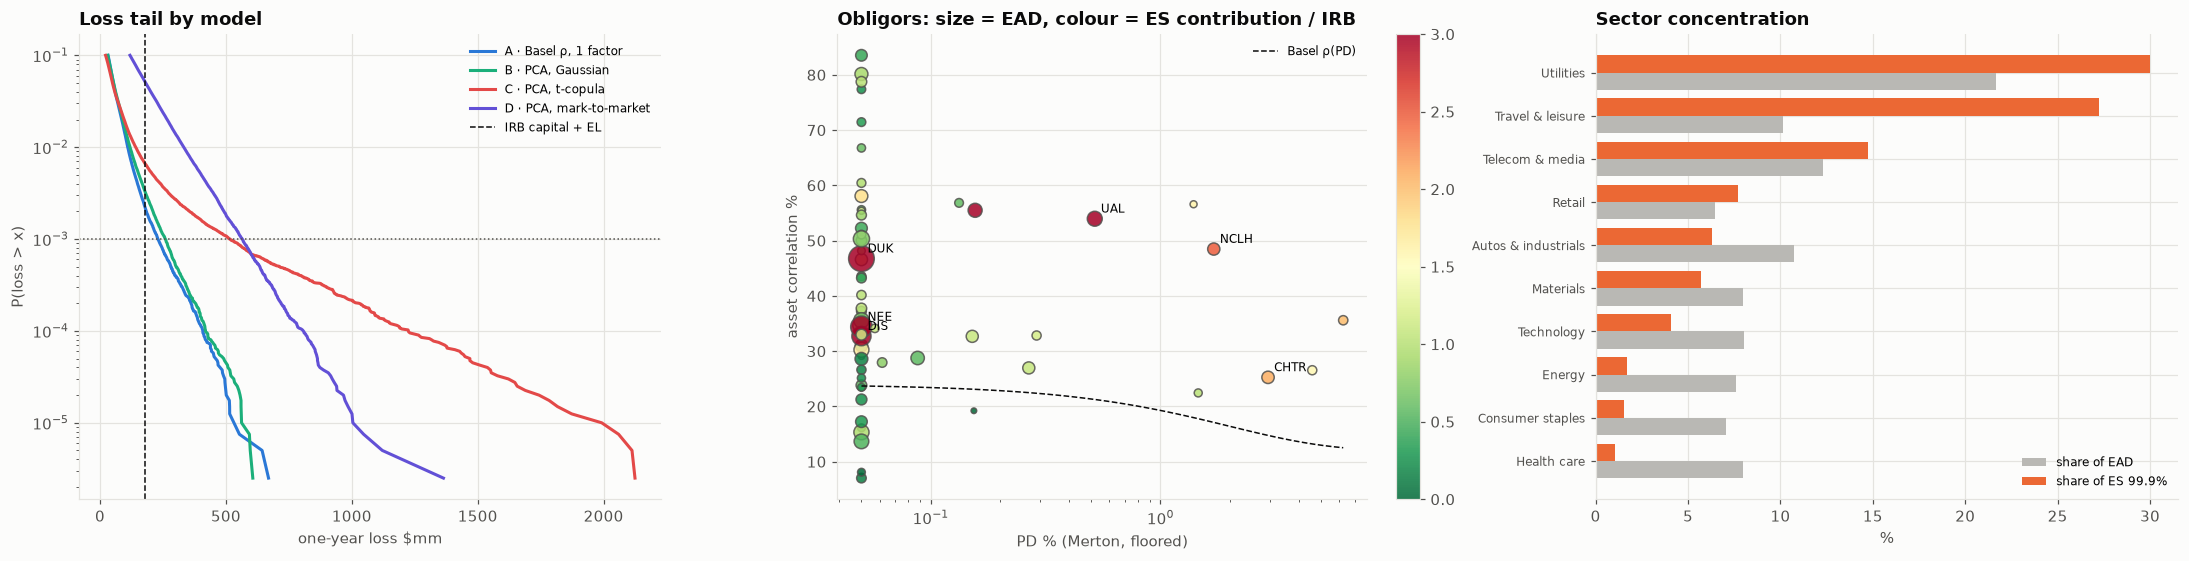

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))
ax = axes[0]
for (label, L), col in zip(
    sims.items(), [PALETTE[0], PALETTE[2], PALETTE[7], PALETTE[6]]
):
    xs = np.sort(L)[int(0.9 * len(L)) :]
    ax.plot(
        xs,
        1 - np.arange(int(0.9 * len(L)), len(L)) / len(L),
        color=col,
        label=label,
    )
ax.set_yscale("log")
ax.axhline(0.001, color=INK_2, ls=":", lw=1)
ax.axvline(
    irb["IRB capital $mm"] + irb["EL $mm"],
    color=INK,
    ls="--",
    lw=1,
    label="IRB capital + EL",
)
ax.set_xlabel("one-year loss $mm")
ax.set_ylabel("P(loss > x)")
ax.set_title("Loss tail by model")
ax.legend(fontsize=8)
ax = axes[1]
sc = ax.scatter(
    ob["PD %"],
    ob["PCA R² (asset correlation)"],
    s=ob["EAD $mm"] / 2,
    c=ob["ES contribution / IRB capital"],
    cmap="RdYlGn_r",
    vmin=0,
    vmax=3,
    alpha=0.85,
    edgecolor=INK_2,
)
grid = np.logspace(np.log10(PD_FLOOR * 100), np.log10(ob["PD %"].max()), 50)
wg = (1 - np.exp(-50 * grid / 100)) / (1 - np.exp(-50))
ax.plot(
    grid,
    (0.12 * wg + 0.24 * (1 - wg)) * 100,
    color=INK,
    ls="--",
    lw=1,
    label="Basel ρ(PD)",
)
for t, r_ in (
    ob.sort_values("ES contribution $mm", ascending=False).head(6).iterrows()
):
    ax.annotate(
        t,
        (r_["PD %"], r_["PCA R² (asset correlation)"]),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points",
    )
ax.set_xscale("log")
ax.set_xlabel("PD % (Merton, floored)")
ax.set_ylabel("asset correlation %")
ax.set_title("Obligors: size = EAD, colour = ES contribution / IRB")
ax.legend(fontsize=8)
plt.colorbar(sc, ax=ax, fraction=0.04)
ax = axes[2]
bsx = by_sector.sort_values("share of ES %")
yi = np.arange(len(bsx))
ax.barh(
    yi - 0.2, bsx["share of EAD %"], 0.4, color="#b9b8b4", label="share of EAD"
)
ax.barh(
    yi + 0.2,
    bsx["share of ES %"],
    0.4,
    color=PALETTE[1],
    label="share of ES 99.9%",
)
ax.set_yticks(yi, bsx.index, fontsize=8)
ax.set_xlabel("%")
ax.set_title("Sector concentration")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "01_loss_tail_obligors_sectors")
plt.show()

## 10. Reading the results and limitations

A $7.1bn book of 60 senior unsecured three-year loans to U.S. companies (effective number of names 38), as of 16 October 2026:

**Merton PDs separate the weak names but cannot rank the strong ones.** The riskiest obligors are Kohl's (PD 6.2%, distance to default 1.5), Cleveland-Cliffs (4.6%), Charter (2.9%), Norwegian Cruise Line (1.7%), Goodyear (1.5%) and American Airlines (1.4%). All are highly levered with equity volatility around 50–70%.

But 44 of 60 obligors have Merton PDs below the 5 bp floor, including BBB names such as AT&T, Verizon and Comcast. The pure Merton model is known to understate investment-grade PDs; that is why KMV maps distance to default to *empirical* default frequencies. A production version would add that calibration step.

- **IRB capital is modest.** IRB capital is $171mm, an average risk weight of 30%, because most of the book sits at the PD floor. Expected loss is only $8mm.
- **Concentration alone adds 30%.** Simulating the same Basel correlations on these 60 actual loans (run A) gives economic capital of $222mm, **1.30× IRB**. The IRB formula assumes infinite granularity, and this book has a few very large tickets. The probability that losses exceed IRB capital plus EL is 0.22%, more than twice the 0.1% the formula targets.

**Real correlations add more.** The PCA factor model gives an average asset correlation (systematic R²) of 40%, against Basel's 12–24%: 76% for energy, 53% for travel and leisure, 50% for consumer staples. With these correlations and three factors (run B), economic capital is $251mm, 1.47× IRB. Equity correlations probably overstate asset correlations for default purposes (Basel's ρ is calibrated to default data), so run B is a stressed but defensible view.

**Fat tails dominate everything else.** A t-copula with 4 degrees of freedom (run C) keeps the same correlations and expected loss but makes defaults cluster in bad states. The 99.9% loss doubles to $516mm and economic capital is **2.97× IRB**; ES 99.9% is $814mm. This is the model-risk band a credit committee should see: the Gaussian assumption alone is worth about $250mm of capital here.

**Migration risk is as large as tail default risk.** In mark-to-market mode (run D) a surviving loan loses value when its distance to default falls. Economic capital is $558mm (3.26× IRB), and losses exceed IRB capital plus EL in 5% of years. For a book that is marked to market or sold before maturity (a bond portfolio, a syndication pipeline), default-mode capital misses most of the risk.

- **Where the tail sits.** Two concentrations drive the expected shortfall:
  - **Single name.** Duke Energy is the largest exposure ($563mm, 8% of the book). Even at a 5 bp PD it contributes $69mm of ES, 7.6 times its IRB capital. Utilities are 22% of EAD and 30% of ES.
  - **Correlated sector.** Travel and leisure is 10% of EAD and 27% of ES: high PDs plus 53% correlation. United Airlines contributes 3.5 times its IRB capital and Carnival 3.4 times.

Health care, staples and energy carry 23% of EAD but 4% of ES. The actions are a single-name limit for the largest utility ticket and a sector limit (or hedge) for airlines and cruise lines. Neither shows up in the additive IRB number.

**Limitations**

- Merton PDs are risk-neutral, use a one-year horizon and a KMV default point, and are not calibrated to observed defaults; most investment-grade names hit the floor.
- Exposures are synthetic (lognormal sizes on real names); LGD is independent of the cycle, although downturn LGDs are higher.
- The PCA factors come from three years of weekly equity returns, which include the 2025–26 market moves; correlations estimated in another window would differ.

In [10]:
ob.to_csv(OUT_DIR / "obligors_pd_correlation_capital.csv")
summary.to_csv(OUT_DIR / "capital_comparison.csv")
by_sector.to_csv(OUT_DIR / "sector_risk_contributions.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_loss_tail_obligors_sectors.png, capital_comparison.csv, obligors_pd_correlation_capital.csv, sector_risk_contributions.csv


## References

### Finance and regulation

- Gordy, M. B. (2003). A risk-factor model foundation for ratings-based bank capital rules. *Journal of Financial Intermediation, 12*(3), 199–232. https://doi.org/10.1016/S1042-9573(03)00040-8
- Merton, R. C. (1974). On the pricing of corporate debt: The risk structure of interest rates. *The Journal of Finance, 29*(2), 449–470. https://doi.org/10.1111/j.1540-6261.1974.tb03058.x
- Basel Committee on Banking Supervision. (2005). *An explanatory note on the Basel II IRB risk weight functions*. Bank for International Settlements. https://www.bis.org/bcbs/irbriskweight.htm
- Frey, R., & McNeil, A. J. (2003). Dependent defaults in models of portfolio credit risk. *Journal of Risk, 6*(1), 59–92. https://doi.org/10.21314/JOR.2003.089
- Bharath, S. T., & Shumway, T. (2008). Forecasting default with the Merton distance to default model. *The Review of Financial Studies, 21*(3), 1339–1369. https://doi.org/10.1093/rfs/hhn044

### Machine learning and deep learning

- Glasserman, P. (2004). *Monte Carlo methods in financial engineering*. Springer. https://doi.org/10.1007/978-0-387-21617-1
- Jolliffe, I. T., & Cadima, J. (2016). Principal component analysis: A review and recent developments. *Philosophical Transactions of the Royal Society A, 374*(2065), 20150202. https://doi.org/10.1098/rsta.2015.0202
- Demarta, S., & McNeil, A. J. (2005). The t copula and related copulas. *International Statistical Review, 73*(1), 111–129. https://doi.org/10.1111/j.1751-5823.2005.tb00254.x